In [1]:
import os
from dotenv import load_dotenv
from google import genai

load_dotenv(override=True)

api_key = os.getenv("GEMINI_API_KEY")

if not api_key:
    raise ValueError("API Key not found in .env")

client = genai.Client(api_key=api_key)

from langchain_core.messages import HumanMessage, SystemMessage, AIMessage
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser , PydanticOutputParser

from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage, SystemMessage, AIMessage

llm = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0)

In [3]:
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain.tools import tool
from langchain.agents import create_agent

llm_gemini = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0
)

@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integers and return the result."""
    return a * b

tools = [multiply]

agent = create_agent(
    model=llm_gemini,
    tools=tools)

In [ ]:
result = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "What is 125 multiplied by 24?"
        }
    ]
})


In [7]:

from rich.console import Console
from rich.panel import Panel

console = Console()

result = agent.invoke({
    "messages": [
        {
            "role": "user",
            "content": "What is 125 multiplied by 24?"
        }
    ]
})

# استخراج آخر رسالة
last_message = result["messages"][-1]

# عرض محتوى الرسالة كنص
console.print(
    Panel(
        str(last_message.content),
        title="[bold cyan]Gemini Response[/bold cyan]",
        border_style="cyan",
        padding=(1, 2)
    )
)


╭──────────────────────────────────────────────── Gemini Response ────────────────────────────────────────────────╮
│                                                                                                                 │
│  [{'type': 'text', 'text': '125 multiplied by 24 is 3,000.', 'extras': {'signature':                            │
│  'EpkBCpYBAWkUfRN50QCUzEITPL3pb/KtkGNmOyhy5T+DwxbsJ3tCpjlURB5EeIy+VeO1cGkvo61MPj8QvBSXGDhmY6SoFUk+qTfIsxVMkuh8  │
│  rwS+/fkkHmEa+S/IAU1raCzjyFuDnvIcojiDCw9i5wGKNkLnXQYG2RCGAxeffxTdrA7OFFq/dWFVXcacTmcAYrWKHkbFjcR2Xqp/'}}]       │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [8]:

from rich.console import Console
from rich.panel import Panel

console = Console()

for message in result["messages"]:
    console.print(
        Panel(
            str(message.content),
            title=message.__class__.__name__,
            border_style="cyan",
            padding=(1, 2)
        )
    )


╭───────────────────────────────────────────────── HumanMessage ──────────────────────────────────────────────────╮
│                                                                                                                 │
│  What is 125 multiplied by 24?                                                                                  │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────── AIMessage ───────────────────────────────────────────────────╮
│                                                                                                                 │
│  []                                                                                                             │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭────────────────────────────────────────────────── ToolMessage ──────────────────────────────────────────────────╮
│                                                                                                                 │
│  3000                                                                                                           │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────── AIMessage ───────────────────────────────────────────────────╮
│                                                                                                                 │
│  [{'type': 'text', 'text': '125 multiplied by 24 is 3,000.', 'extras': {'signature':                            │
│  'EpkBCpYBAWkUfRN50QCUzEITPL3pb/KtkGNmOyhy5T+DwxbsJ3tCpjlURB5EeIy+VeO1cGkvo61MPj8QvBSXGDhmY6SoFUk+qTfIsxVMkuh8  │
│  rwS+/fkkHmEa+S/IAU1raCzjyFuDnvIcojiDCw9i5wGKNkLnXQYG2RCGAxeffxTdrA7OFFq/dWFVXcacTmcAYrWKHkbFjcR2Xqp/'}}]       │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [ ]:
print(result)

{'messages': [HumanMessage(content='What is 125 multiplied by 24?', additional_kwargs={}, response_metadata={}, id='82e4d747-97f6-4d97-ae1b-7ac55c4387c5'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'multiply', 'arguments': '{"a": 125, "b": 24}'}, '__gemini_function_call_thought_signatures__': {'call_4626390': 'EoACCv0BAWkUfROhUxfrxZbJ4m5Qh4gqCDrA+NzfpMxujnRCMKB9KAfm7EwqG9hlrp4wZozXCOo6KlBaiozuyCq3U1ERbFF6NNZeh8aFzVnv5mCQXscaThIxkBL97KfnuFCil1ABgFZqPY4ieLQ2ugQtc84MdV/ZmgfT1tpWD3huUuWJXQ1fWnqqHkD+kDXRXpD0dPqazFPe4w0l2vWARgXLkUF3loZFIA3nAEXi4vqJPYOAm/6ieO3jN5ThpNTww/uAfk5VbBsd1lwOfl3ac5t69AEWypTjXq7kShT5DdLYuYvVMmhQ9IbfRnqyGw/p7EvVS+snXIMFjfd3QYZu//ICzA=='}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.8-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a15417-1e15-77f1-a75e-28e56bcd7e93-0', tool_calls=[{'name': 'multiply', 'args': {'a': 125, 'b': 24}, 'id': 'call_4626390', 'type': 'tool_call'}], invalid_tool_ca

# **Tools**

In [10]:
# TOOL - 1 [News Search Tool]

from langchain_community.tools import DuckDuckGoSearchRun

search_tool = DuckDuckGoSearchRun(description="This is a tool to search the web for news")


# TOOL - 2 [Wikipedia Search Tool]

from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper

wikipedia_tool = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper(),description="This is a tool to search Wikipedia")


# TOOL - 3 [Custom Enterprise Tool]

from langchain.tools import tool

@tool
def enterprise_tool(query:str)-> str:

    """This is a tool to send emails to employees"""
    
    return "Email Sent"

In [11]:
ToolKit = [search_tool, wikipedia_tool, enterprise_tool]
ToolKit

[DuckDuckGoSearchRun(description='This is a tool to search the web for news', api_wrapper=DuckDuckGoSearchAPIWrapper(region='wt-wt', safesearch='moderate', time='y', max_results=5, backend='auto', source='text')),
 WikipediaQueryRun(description='This is a tool to search Wikipedia', api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from 'e:\\LangChain_Practice\\.venv\\Lib\\site-packages\\wikipedia\\__init__.py'>, top_k_results=3, lang='en', load_all_available_meta=False, doc_content_chars_max=4000)),
 StructuredTool(name='enterprise_tool', description='This is a tool to send emails to employees', args_schema=<class 'langchain_core.utils.pydantic.enterprise_tool'>, func=<function enterprise_tool at 0x000001ED923A9EE0>)]

# **ReAct Agent**

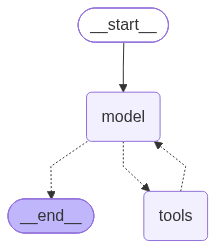

In [13]:
from langchain.agents import create_agent
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(
    model="gemini-3.8-flash",
    temperature=0.1,
    max_tokens=1000,
    timeout=30
)
agent = create_agent(model, tools=ToolKit)
agent

# **ReAct Agent Invoke With Streams**

In [14]:
for chunk in agent.stream(
    {
        "messages": [
            {
                "role": "user",
                "content": "Give me the latest stock market news."
            }
        ]
    },
    stream_mode="values"
):
    print(chunk)

{'messages': [HumanMessage(content='Give me the latest stock market news.', additional_kwargs={}, response_metadata={}, id='e955e53f-466f-4f58-a5af-ab34e02d934e')]}
{'messages': [HumanMessage(content='Give me the latest stock market news.', additional_kwargs={}, response_metadata={}, id='e955e53f-466f-4f58-a5af-ab34e02d934e'), AIMessage(content=[], additional_kwargs={'function_call': {'name': 'duckduckgo_search', 'arguments': '{"query": "latest stock market news today"}'}, '__gemini_function_call_thought_signatures__': {'call_987337': 'ErIDCq8DAWkUfRN/8vf2F69E1zxfmFoSj7VlRW3dW/4ivrJ9JhY4xhbXEAC3tAff9+trD6/b55URthy86slfrWY+t7YjT7BxAoluuULW8LYWhdGH2sP8qnd+b+WVx17sJPS95oT8R5tYXa/e2f2PXCTm3mc+zi9A8fGrs2QTHV9FUH5Oo46PF0N+MzCHFDskKxXso3bR+R42kV+uvta1Wp38q+sSuAp0Dn4StAMck7cylI5j70QnyXgpLofpkE++jycmQP0Gt8wY6MBTj4OoJCcLs8SQwahiokLPEM36KPwDVgVyuZ+ci6YXH6AsHcMtHcxym+cMqvgXkgW2XD/dsdmnrXwEi5KRtGJLsP8/CpnwSUoDh3vJHj7kyRjkJ3o4iLp3iUQqxaEVCh+nD/dyP0qnigOO/BUaXXiZrzUvW4IBDbz80+7yQT4bYbl2RvjIiMq86RjiQi

DDGSException: DNSError: DNSError('error sending request for url (https://wt.wikipedia.org/w/api.php?action=opensearch&profile=fuzzy&limit=1&search=US%20stocks%20market%20wrap%20today%20financial%20news) > error resolving DNS > DNS error: no records found for Query { name: Name("wt.wikipedia.org."), query_type: A, query_class: IN }')

In [16]:

import socket
import requests

for host in ["en.wikipedia.org", "wt.wikipedia.org"]:
    try:
        print(host, "->", socket.gethostbyname(host))
    except socket.gaierror as e:
        print(host, "DNS FAILED:", e)

try:
    r = requests.get(
        "https://en.wikipedia.org/w/api.php",
        params={
            "action": "query",
            "meta": "siteinfo",
            "format": "json"
        },
        timeout=10
    )
    print("Wikipedia API:", r.status_code)
except requests.RequestException as e:
    print("Request failed:", e)


en.wikipedia.org -> 185.15.58.224
wt.wikipedia.org DNS FAILED: [Errno 11001] getaddrinfo failed
Wikipedia API: 403


In [17]:
print(search_tool.invoke("latest stock market headlines"))

Find the latest stock market news from every corner of the globe at Reuters.com, your online source for breaking international market and finance news Find the latest stock market news from every corner of the globe at Reuters.com, your online source for breaking international market and finance news Read the latest business headlines and today's market news coverage from CNBC. Stock Market Today highlights the latest stock market news and analysis. Updated throughout each session, it also include stock futures. See the latest on US Stocks. From breaking news to in-depth reporting, Bloomberg tracks the full story in real time.


In [18]:
result = search_tool.invoke(
    "latest stock market news today S&P 500 Nasdaq Dow Jones Reuters"
)
print(result)

S&P 500 and Nasdaq futures gained on Monday as AI-related shares rebounded from last week's sharp selloff, while a decline in oil prices and Treasury yields provided additional support ahead of ... Find the latest stock market news from every corner of the globe at Reuters.com, your online source for breaking international market and finance news Find the latest stock market news from every corner of the globe at Reuters.com, your online source for breaking international market and finance news So far in 2026, the Dow is up 8.2%, while the S&P 500 and Nasdaq are up 11.9% and 12.5%, respectively. Semiconductor stocks edged lower, deepening a sell-off in chips over the past week. What does the US stock market today snapshot include? It includes the latest cached S&P 500, Nasdaq Composite, Dow Jones, Russell 2000 and VIX levels, plus leading gainers and losers.


In [19]:
example_query = "Give me the latest news about the stock market"

events = agent.stream(
    {"messages": [("user", example_query)]},
    stream_mode="values",
)
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

Give me the latest news about the stock market
================================== Ai Message ==================================

[]
Tool Calls:
  duckduckgo_search (call_4278148)
 Call ID: call_4278148
  Args:
    query: latest stock market news today
================================= Tool Message =================================
Name: duckduckgo_search

Share Market Today | Share Market Live updates: Get all the Latest Share Market News and Updates on The Economic Times. Share Market Live Charts, News, Analysis, IPO News and more. Find the latest stock market news from every corner of the globe at Reuters.com, your online source for breaking international market and finance news Read the latest business headlines and today's market news coverage from CNBC. See the latest on US Stocks. From breaking news to in-depth reporting, Bloomberg tracks the full story in real time. Track the latest stock market ne

# **Manually Binding The LLM With Tools**

In [ ]:
# Without Binding
llm.invoke("What's the latest news about the stock market?")

AIMessage(content='I can’t fetch live news or real‑time quotes (my training data goes to June 2024), so I can’t give a current market snapshot for today. I can, however, help you get the latest market news right now or give a concise, up‑to‑date (to June 2024) summary of major market themes and how to interpret new headlines. Which would you prefer?\n\nIf you want the latest immediately, here are quick ways to get it and what to check:\n\n1) Fast places to see a market snapshot (real‑time or near real‑time)\n- Google: search “S&P 500” / “Dow” / “Nasdaq” / or a ticker.\n- Yahoo Finance, MSN Money, CNBC Markets, MarketWatch, Investing.com, TradingView.\n- For headlines: Reuters Markets, Bloomberg Markets, WSJ Markets, CNBC.\n\n2) Key things to look at on a snapshot page\n- Index moves: S&P 500, Dow, Nasdaq (and percent change).\n- Volatility: VIX.\n- Treasury yields: 2‑yr and 10‑yr (moves in yields drive risk assets).\n- Major sectors: tech, financials, energy, etc., to see which are lea

In [ ]:
# With Binding
llm_binded = llm.bind_tools(ToolKit)
llm_binded.invoke("What's the latest news about the stock market?")

AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 344, 'prompt_tokens': 200, 'total_tokens': 544, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 256, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-5-mini-2025-08-07', 'system_fingerprint': None, 'id': 'chatcmpl-CvqiL7oAHH8WIFfmMDPORpkHB9OPH', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019b9f40-8721-7ef3-9028-1e6ade99e114-0', tool_calls=[{'name': 'duckduckgo_search', 'args': {'query': 'stock market news today'}, 'id': 'call_z8dyLPcPPQ7Phm5k6VHwj9VX', 'type': 'tool_call'}, {'name': 'duckduckgo_search', 'args': {'query': 'S&P 500 today'}, 'id': 'call_CIbZNHHr29WRCyBEntyZNlWs', 'type': 'tool_call'}, {'name': 'duckduckgo_search', 'args': {'query': 'Dow Jones Industrial Average ne